# 02 — Regulons, causal flows, states and programs (MINER)

Runs MINER on one cancer: mutation matrix → co-expression clusters → regulons (TF + co-expressed target genes) → causal flows (mutation → TF → regulon) → discrete regulon activity → transcriptional states (patient groups) → transcriptional programs (regulon groups).
`{prefix}` = `CANCER.lower()` (e.g. `brca`). **The cancer and all paths are set in `config.py`; nothing in this notebook needs editing for a new cancer.** Clustering and causal inference are the slow steps.

## Inputs

| File | From | Format |
|---|---|---|
| `BASE_DIR/{prefix}_log2tpm.csv` | 01 | genes (symbols) × patients; log2(TPM+1) |
| `BASE_DIR/{prefix}_zscored.csv` | 01 | genes (symbols) × patients; only the patient IDs (header) are read |
| `BASE_DIR/mc3.v0.2.8.PUBLIC.maf` | TCGA MC3 (GDC PanCanAtlas) | one row per mutation, all cancers; `Hugo_Symbol`, `Variant_Classification`, `Tumor_Sample_Barcode`, ... |
| `miner/data/identifier_mappings.txt` | miner package | Ensembl ↔ gene symbol / synonym mapping |
| `miner/data/network_dictionaries/tfbsdb_tf_to_genes.pkl` | miner package | `{TF: [genes with a binding site for it]}` |

## Outputs (in `{prefix}_output/` unless noted)

| File | Format |
|---|---|
| `BASE_DIR/{prefix}_mutation_matrix.csv` | genes (symbols) × patients; 1 = coding mutation, 0 = none; genes mutated in ≥ 5% of patients **and** called a driver for this cancer (see below) |
| `BASE_DIR/{prefix}_mutation_matrix_all.csv` | same format; every gene mutated in ≥ 5% of patients, before the driver restriction |
| `mutation_filter_log.csv` | one row per gene passing the 5% filter: `n_patients_mutated`, `frequency`, `Tier` (known / candidate / provisional / none), `kept` |
| `coexpressionDictionary.json` | `{cluster ID: [Ensembl gene IDs]}` |
| `mechanisticOutput.json`, `coregulationModules.json`, `coexpressionModules.json` | miner intermediates of the TF → cluster inference |
| `regulons.json` | `{regulon ID (str): [Ensembl gene IDs]}` |
| `regulonDf.csv` | one row per (regulon, TF, gene); columns `Regulon_ID`, `Regulator`, `Gene` |
| `eigengenes.csv` | regulons × patients; PC1 activity score |
| `causal_analysis/` + `completeCausalResults.csv` | one row per causal flow (mutation → regulator → regulon) with its test statistics |
| `filteredCausalResults.csv` | same columns; only flows passing all four paper criteria; used by 06 |
| `overExpressedMembers.csv`, `underExpressedMembers.csv` | regulons × patients; 1/0 (regulon over- / under-active in that patient); used by 05 |
| `transcriptional_states.json` | `{state number: [patient IDs]}` |
| `state_coherence_check.csv` | one row per state; `n_patients`, `within_corr`, `null_mean`, `null_std`, `z_score` |
| `transcriptional_programs.json` | `{program number: [regulon IDs]}` |
| `regulons_activity_heatmap.csv` (+ `regulon_activity_heatmap.pdf`) | eigengenes reordered by program (rows) and state (columns) |
| `transcriptional_programs.pdf`, `programs_vs_states.csv` / `.pdf` | program activity summaries; programs × states |



## Deviation from the paper: driver restriction of the mutation matrix

The paper tests every gene mutated in ≥ 5% of patients. In heavily mutated cancers that is hundreds to thousands of genes (LUAD 785, UCEC 5,027), almost all passengers whose mutation status tracks total mutation burden, and it produces millions of confounded causal flows. With `RESTRICT_TO_DRIVERS = True` the genes are limited to published driver calls for this cancer, taken from Open Targets by `driver_tiers.py`: a gene must be called a driver of this cancer by IntOGen (Martínez-Jiménez et al. 2020); **known** = also a Cancer Gene Census gene (Sondka et al. 2018), **candidate** = not in the Cancer Gene Census. Background: Lawrence et al. 2013 (frequency alone does not identify drivers), Martincorena et al. 2017 (dNdScv). The list is cached in `{prefix}_data/driver_genes.csv`; `mutation_filter_log.csv` records what was kept and dropped. If the tier printed is `provisional`, Open Targets could not be reached and a built-in fallback list was used: do not run causal inference on that list for final results.

> **GBM note.** GBM expression comes from `01_gbm_expression` (RNA-seq and microarray patients, z-scored within platform), not from recount3. `gbm_zscored.csv` is the matrix MINER runs on; `gbm_log2tpm.csv` holds the RNA-seq patients only.

The last section adds miRNA regulators (outputs `mirna_regulons.json`, `mirna_regulonDf.csv`, `mirna_eigengenes.csv`, `mirna_regulon_regulators.csv`, `mirna_completeCausalResults.csv`, `mirna_filteredCausalResults.csv`).

**Pathway mutations.** With `config.INCLUDE_PATHWAY_MUTATIONS` on, NCI-Nature pathways mutated in at least 5% of patients are added to the mutation matrix and tested like genes (outputs `gbm_pathway_mutation_matrix.csv`, `pathway_mutation_log.csv`). In the causal results their names start with `PID_`.


In [1]:
# Necessary imports
import os
import time
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import miner.miner as miner

from miner import *
from miner.miner import *
from sklearn.decomposition import PCA
from miner import causal_inference as causalinf
from miner.subtypes import inferSubtypes

# Repository root: holds config.py (paths and per-cancer settings) and driver_tiers.py
import sys
repo_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if repo_dir not in sys.path:
    sys.path.insert(0, repo_dir)
import config

# CANCER CONFIGURATION: the cancer and the data root come from config.py
CANCER     = config.CANCER

# folder holding this cancer's run (expression files from 01 live here)
base_dir   = config.BASE_DIR

# this cancer's own folder: holds <prefix>_data, <prefix>_notebooks and <prefix>_output
cancer_dir = os.path.join(base_dir, CANCER.lower())

# this cancer's expression / mutation files (written by 01 and 02)
data_dir   = os.path.join(cancer_dir, f"{CANCER.lower()}_data")
prefix     = CANCER.lower()
output_dir = os.path.join(cancer_dir, f"{prefix}_output")

# MC3 somatic mutation file (TCGA pan-cancer, all cancers in one MAF, so it is shared across cancers)
maf_path = config.MAF_PATH

# Expression files written by 01 and the mutation matrix written by this notebook
log2_path    = os.path.join(data_dir, f"{prefix}_log2tpm.csv")
zscored_path = os.path.join(data_dir, f"{prefix}_zscored.csv")
mut_path     = os.path.join(data_dir, f"{prefix}_mutation_matrix.csv")

# miner's own data files: gene ID mappings and the TF binding site database
miner_dir  = os.path.dirname(miner.__file__)
idmap_path = os.path.join(miner_dir, "data", "identifier_mappings.txt")
tfdb_path  = os.path.join(miner_dir, "data", "network_dictionaries", "tfbsdb_tf_to_genes.pkl")

# Driver gene tiers: published driver calls per cancer (module driver_tiers.py in the repository root, shared by 02, 06 and 07)
from driver_tiers import get_driver_tiers

# Default False = the paper's rule. True: causal inference is run only on driver genes (tiers "known" and "candidate") among the genes mutated in >= 5% of patients
# False: every gene mutated in >= 5% of patients is tested, as in the paper (in heavily mutated cancers this is thousands of passengers)
RESTRICT_TO_DRIVERS = config.RESTRICT_TO_DRIVERS

# every gene passing the 5% filter, before the driver restriction (kept for reference)
mut_all_path = os.path.join(data_dir, f"{prefix}_mutation_matrix_all.csv")

os.makedirs(output_dir, exist_ok=True)
assert os.path.exists(maf_path), f"missing MAF: {maf_path}"
assert os.path.exists(log2_path), f"missing expression file (run 01 first): {log2_path}"
print(f"Cancer: {CANCER} | outputs: {output_dir}")

size_gb = os.path.getsize(maf_path) / (1024**3)
print(f"File size: {size_gb:.2f} GB")

# Peek at raw lines first — MAF files can have leading '#' comment lines before the real header
with open(maf_path, "rt") as f:
    for i in range(5):
        line = f.readline()
        print(f"Line {i}: {line[:300]}")

Cancer: GBM | outputs: data\gbm\gbm_output
File size: 3.49 GB
Line 0: Hugo_Symbol	Entrez_Gene_Id	Center	NCBI_Build	Chromosome	Start_Position	End_Position	Strand	Variant_Classification	Variant_Type	Reference_Allele	Tumor_Seq_Allele1	Tumor_Seq_Allele2	dbSNP_RS	dbSNP_Val_Status	Tumor_Sample_Barcode	Matched_Norm_Sample_Barcode	Match_Norm_Seq_Allele1	Match_Norm_Seq_Allele2
Line 1: TACC2	0	.	GRCh37	10	123810032	123810032	+	Missense_Mutation	SNP	C	C	T	rs540521848	.	TCGA-02-0003-01A-01D-1490-08	TCGA-02-0003-10A-01D-1490-08	C	C	.	.	.	.	.	.	.	.	.	.	.	.	.	.	.	c.113C>T	p.Thr38Met	p.T38M	ENST00000369005	3/23	43	4	38	74	74	0	TACC2,missense_variant,p.Thr38Met,ENST00000358010,;TACC2,mis
Line 2: JAKMIP3	0	.	GRCh37	10	133967449	133967449	+	Silent	SNP	C	C	T	rs763531628	.	TCGA-02-0003-01A-01D-1490-08	TCGA-02-0003-10A-01D-1490-08	C	C	.	.	.	.	.	.	.	.	.	.	.	.	.	.	.	c.2169C>T	p.%3D	p.D723D	ENST00000298622	18/24	82	16	65	123	123	0	JAKMIP3,synonymous_variant,p.%3D,ENST00000298622,;JAKMIP3,non_coding
Line 3: PAN

In [2]:
# Patient IDs of this cancer, from the expression data
cancer_patients = set(pd.read_csv(zscored_path, index_col=0, nrows=0).columns.tolist())
print(f"{CANCER} patients from expression data: {len(cancer_patients)}")

# The MAF is large, so read it in chunks, keeping only the needed columns and only this cancer's patients
usecols = ["Hugo_Symbol", "Chromosome", "Variant_Classification", "Tumor_Sample_Barcode", "NCBI_Build"]
chunks = []
total_rows = 0

for chunk in pd.read_csv(maf_path, sep="\t", comment="#", usecols=usecols, chunksize=500_000, low_memory=False):
    total_rows += len(chunk)
    chunk = chunk.copy()

    # Patient ID = first 3 fields of the tumour sample barcode (TCGA-XX-XXXX)
    chunk["patient_id"] = chunk["Tumor_Sample_Barcode"].apply(lambda x: "-".join(str(x).split("-")[:3]))
    chunk_cancer = chunk[chunk["patient_id"].isin(cancer_patients)]
    if len(chunk_cancer):
        chunks.append(chunk_cancer)

mutations_cancer = pd.concat(chunks, ignore_index=True)
print(f"Total MC3 rows scanned: {total_rows}")
print(f"{CANCER}-patient mutation rows: {len(mutations_cancer)}")
print(f"Unique {CANCER} patients with any mutation: {mutations_cancer['patient_id'].nunique()}")
print(f"\nNCBI_Build values: {mutations_cancer['NCBI_Build'].unique()}")
print(f"\nVariant_Classification value counts:")
print(mutations_cancer["Variant_Classification"].value_counts())

GBM patients from expression data: 550
Total MC3 rows scanned: 3600963
GBM-patient mutation rows: 66585
Unique GBM patients with any mutation: 351

NCBI_Build values: ['GRCh37']

Variant_Classification value counts:
Variant_Classification
Missense_Mutation         38760
Silent                    14860
3'UTR                      3256
Nonsense_Mutation          3109
Intron                     1654
5'UTR                      1335
Splice_Site                1028
RNA                         785
Frame_Shift_Del             690
Frame_Shift_Ins             369
3'Flank                     236
5'Flank                     220
In_Frame_Del                179
Translation_Start_Site       41
Nonstop_Mutation             38
In_Frame_Ins                 25
Name: count, dtype: int64


In [3]:
# Protein-altering (coding) mutation classes; silent and non-coding mutations are dropped
coding_mutations = [
    "Missense_Mutation",
    "Nonsense_Mutation",
    "Frame_Shift_Del",
    "Frame_Shift_Ins",
    "In_Frame_Del",
    "In_Frame_Ins",
    "Splice_Site",
    "Translation_Start_Site",
    "Nonstop_Mutation"
]

mutations_coding = mutations_cancer[mutations_cancer["Variant_Classification"].isin(coding_mutations)]
print(f"{CANCER} mutation rows before coding filter: {len(mutations_cancer)}")
print(f"{CANCER} mutation rows after coding filter: {len(mutations_coding)}")
print(f"Unique patients after coding filter: {mutations_coding['patient_id'].nunique()}")

# Build binary mutation matrix (genes x patients)
mutation_matrix = mutations_coding.groupby(["Hugo_Symbol", "patient_id"]).size().unstack(fill_value=0)
mutation_matrix = (mutation_matrix > 0).astype(int)
print(f"\nInitial mutation matrix: {mutation_matrix.shape}")

# Apply 5% frequency filter (paper: "mutated in at least 5% of the patient tumors")
n_patients = mutation_matrix.shape[1]
min_patients = int(0.05 * n_patients)
print(f"5% of {n_patients} patients = {min_patients} patients minimum")

mutation_freq = mutation_matrix.sum(axis=1)
mutation_matrix_filtered = mutation_matrix[mutation_freq >= min_patients]

print(f"\nGenes before 5% filter: {mutation_matrix.shape[0]}")
print(f"Genes after 5% filter: {mutation_matrix_filtered.shape[0]}")
print(f"\nTop mutated genes:")
print(mutation_freq.sort_values(ascending=False).head(15))

# Every gene passing the 5% filter is saved before any further restriction
mutation_matrix_filtered.to_csv(mut_all_path)
print(f"\nSaved {prefix}_mutation_matrix_all.csv: {mutation_matrix_filtered.shape}")

# Driver restriction (deviation from the paper, which tests every gene mutated in >= 5% of patients)
# Frequency alone cannot separate drivers from passengers in heavily mutated cancers (Lawrence et al. 2013), so the genes
# tested for causal flows are limited to published driver calls for this cancer:
# both tiers need an IntOGen driver call for this cancer: "known" = also in the Cancer Gene Census, "candidate" = not in it
driver_table = get_driver_tiers(CANCER, data_dir)
tier_of = dict(zip(driver_table["Gene"], driver_table["Tier"]))

# One row per gene passing the 5% filter: how often it is mutated, its tier and whether it is kept
filter_log = pd.DataFrame({"n_patients_mutated": mutation_freq[mutation_matrix_filtered.index]})
filter_log["frequency"] = filter_log["n_patients_mutated"] / n_patients
filter_log["Tier"] = [tier_of.get(g, "none") for g in filter_log.index]
if RESTRICT_TO_DRIVERS and len(driver_table) > 0:
    filter_log["kept"] = filter_log["Tier"] != "none"
else:
    filter_log["kept"] = True
    print("No driver restriction applied: every gene passing the 5% filter is kept")
filter_log = filter_log.sort_values("n_patients_mutated", ascending=False)
filter_log.index.name = "Gene"
filter_log.to_csv(os.path.join(output_dir, "mutation_filter_log.csv"))

mutation_matrix_filtered = mutation_matrix_filtered.loc[filter_log.index[filter_log["kept"]]]
print(f"Genes after driver restriction: {mutation_matrix_filtered.shape[0]} of {len(filter_log)} | "
      f"per tier: {filter_log.loc[filter_log['kept'], 'Tier'].value_counts().to_dict()}")
print(filter_log[filter_log["kept"]].round(3).to_string())

# Drivers on the list that are absent here: mutated in < 5% of patients, or mainly altered by copy number / fusion
print("Listed drivers below the 5% filter:", sorted(set(driver_table["Gene"]) - set(filter_log.index)))

mutation_matrix_filtered.to_csv(mut_path)
print(f"\nSaved {prefix}_mutation_matrix.csv")
print(f"Shape: {mutation_matrix_filtered.shape}")
print(f"Genes: {mutation_matrix_filtered.index.tolist()}")


GBM mutation rows before coding filter: 66585
GBM mutation rows after coding filter: 44239
Unique patients after coding filter: 350

Initial mutation matrix: (13878, 350)
5% of 350 patients = 17 patients minimum

Genes before 5% filter: 13878
Genes after 5% filter: 44

Top mutated genes:
Hugo_Symbol
PTEN      112
TP53      111
TTN        92
EGFR       85
MUC16      53
FLG        50
NF1        40
RYR2       40
ATRX       34
RB1        33
PIK3CA     33
SYNE1      33
SPTA1      31
PIK3R1     30
OBSCN      28
dtype: int64

Saved gbm_mutation_matrix_all.csv: (44, 350)
Driver genes for GBM loaded from cache: {'known': 45, 'candidate': 3}
IntOGen score >= 0.6: 12 of 48 driver calls kept: {'known': 12}
No driver restriction applied: every gene passing the 5% filter is kept
Genes after driver restriction: 44 of 44 | per tier: {'none': 35, 'known': 9}
         n_patients_mutated  frequency   Tier  kept
Gene                                               
PTEN                    112      0.320  kn

In [4]:
# Pathway mutations (as in the paper): a pathway counts as mutated in a patient if at least one of its member genes
# has a coding mutation. Different patients often hit the same pathway through different genes, each too rare to test alone
INCLUDE_PATHWAYS = config.INCLUDE_PATHWAY_MUTATIONS
pathway_path = os.path.join(data_dir, f"{prefix}_pathway_mutation_matrix.csv")

if INCLUDE_PATHWAYS:
    # miner's pathway database: {pathway name: [Ensembl gene IDs]}. The paper uses the NCI-Nature pathways (names start with PID_)
    pathway_db = miner.read_pkl(os.path.join(miner_dir, "data", "network_dictionaries", "pathways.pkl"))
    idmap_p = pd.read_csv(idmap_path, sep="\t", header=0)
    names_p = idmap_p[idmap_p["Source"] == "Gene Name"]
    ensembl_to_symbol_p = dict(zip(names_p["Preferred_Name"], names_p["Name"]))

    # mutation_matrix here still holds EVERY gene (before the 5% filter), which is what a pathway needs
    rows, info = {}, {}
    for name, members in pathway_db.items():
        if not name.startswith(config.PATHWAY_PREFIX):
            continue
        symbols = sorted({ensembl_to_symbol_p[g] for g in members if g in ensembl_to_symbol_p})
        mutated_members = [s for s in symbols if s in mutation_matrix.index]
        if len(mutated_members) == 0:
            continue
        per_gene = mutation_matrix.loc[mutated_members].sum(axis=1)
        rows[name] = (mutation_matrix.loc[mutated_members].sum(axis=0) > 0).astype(int)
        info[name] = {"n_genes": len(symbols), "n_patients_mutated": int(rows[name].sum()),
                      "top_gene": per_gene.idxmax(), "top_gene_patients": int(per_gene.max())}

    pathway_matrix = pd.DataFrame(rows).T
    pathway_log = pd.DataFrame(info).T
    pathway_log["frequency"] = pathway_log["n_patients_mutated"].astype(float) / n_patients

    # Share of the pathway's mutated patients explained by its most mutated gene: close to 1 means the pathway row is
    # nearly a copy of that single gene
    pathway_log["top_gene_share"] = pathway_log["top_gene_patients"].astype(float) / pathway_log["n_patients_mutated"].astype(float)

    # Same 5% rule as for genes. Pathways mutated in nearly everyone are dropped too (not in the paper): with almost no
    # wild-type patients left the mutated-vs-wild-type test is meaningless
    pathway_log["kept"] = (pathway_log["n_patients_mutated"] >= min_patients) & (pathway_log["frequency"] <= config.MAX_PATHWAY_FREQUENCY)
    pathway_log = pathway_log.sort_values("n_patients_mutated", ascending=False)
    pathway_log.index.name = "Pathway"
    pathway_log.to_csv(os.path.join(output_dir, "pathway_mutation_log.csv"))

    pathway_matrix = pathway_matrix.loc[pathway_log.index[pathway_log["kept"]]]
    pathway_matrix.to_csv(pathway_path)
    print(f"Pathways with at least one mutated gene: {len(pathway_log)} | kept (>= 5% and <= {config.MAX_PATHWAY_FREQUENCY:.0%} of patients): {len(pathway_matrix)}")
    print(pathway_log[pathway_log["kept"]].head(15)[["n_genes", "frequency", "top_gene", "top_gene_share"]].round(2).to_string())
else:
    print("Pathway mutations are switched off (config.INCLUDE_PATHWAY_MUTATIONS)")


Pathways with at least one mutated gene: 196 | kept (>= 5% and <= 95% of patients): 191
                                    n_genes  frequency top_gene  top_gene_share
Pathway                                                                        
PID_P53_DOWNSTREAM_PATHWAY              136       0.67     TP53            0.47
PID_SHP2_PATHWAY                         58       0.53     EGFR            0.46
PID_A6B1_A6B4_INTEGRIN_PATHWAY           46       0.53     EGFR            0.46
PID_ERBB1_DOWNSTREAM_PATHWAY            106       0.52     EGFR            0.47
PID_P75_NTR_PATHWAY                      69       0.51     TP53            0.63
PID_AVB3_INTEGRIN_PATHWAY                75       0.50   PIK3CA            0.19
PID_TCPTP_PATHWAY                        44       0.49     EGFR            0.49
PID_REG_GR_PATHWAY                       82       0.48     TP53            0.66
PID_ERBB1_INTERNALIZATION_PATHWAY        42       0.47     EGFR            0.51
PID_ERBB1_RECEPTOR_PROXIMAL_PATH

In [5]:
# Gene symbol -> Ensembl ID conversion (MINER works on Ensembl IDs)
# NOTE: superseded by the next cell, which adds a synonym fallback and overwrites expr_raw / exp_data
miner_dir = os.path.dirname(miner.__file__)
idmap_path = os.path.join(miner_dir, "data", "identifier_mappings.txt")

idmap = pd.read_csv(idmap_path, sep="\t", header=0)
gene_name_map = idmap[idmap['Source'] == 'Gene Name'][['Preferred_Name', 'Name']]
symbol_to_ensembl = dict(zip(gene_name_map['Name'], gene_name_map['Preferred_Name']))
print(f"Symbol->Ensembl mappings: {len(symbol_to_ensembl)}")

# GBM: the platform-wise z-scored matrix from 01 (RNA-seq + microarray patients), not log2 TPM
expr_raw = pd.read_csv(zscored_path, index_col=0)
print(f"Raw matrix: {expr_raw.shape}")

expr_raw.index = [symbol_to_ensembl.get(g, g) for g in expr_raw.index]
converted = [g for g in expr_raw.index if g.startswith('ENSG')]
expr_raw = expr_raw.loc[converted]
print(f"After Ensembl conversion: {expr_raw.shape}")

# Z-score each gene across patients
means = expr_raw.mean(axis=1)
stds = expr_raw.std(axis=1)
exp_data = ((expr_raw.T - means) / stds).T
exp_data = exp_data.loc[stds > 0]
print(f"After z-scoring: {exp_data.shape}")

Symbol->Ensembl mappings: 20055
Raw matrix: (9790, 550)
After Ensembl conversion: (9780, 550)
After z-scoring: (9780, 550)


In [6]:
# Gene symbol -> Ensembl ID conversion with a synonym fallback
idmap = pd.read_csv(idmap_path, sep="\t", header=0)

gene_name_map = idmap[idmap['Source'] == 'Gene Name'][['Preferred_Name', 'Name']]
symbol_to_ensembl = dict(zip(gene_name_map['Name'], gene_name_map['Preferred_Name']))

# Fallback: MINER's own Synonym table, restricted to unambiguous synonyms (map to exactly 1 gene)
syn = idmap[idmap['Source'] == 'Synonym']
syn_counts = syn.groupby('Name')['Preferred_Name'].nunique()
unambiguous_syn = syn_counts[syn_counts == 1].index
syn_unambig = syn[syn['Name'].isin(unambiguous_syn)]
synonym_to_ensembl = dict(zip(syn_unambig['Name'], syn_unambig['Preferred_Name']))

print(f"Primary (Gene Name) mappings: {len(symbol_to_ensembl)}")
print(f"Fallback (unambiguous Synonym) mappings: {len(synonym_to_ensembl)}")

# GBM: the platform-wise z-scored matrix from 01 (RNA-seq + microarray patients), not log2 TPM
expr_raw = pd.read_csv(zscored_path, index_col=0)
print(f"Raw matrix: {expr_raw.shape}")

def resolve(g):

    '''

    Converts one gene symbol to its Ensembl ID. Tries the primary gene name first, then unambiguous synonyms.

    Args: g (str). Gene symbol

    Returns: str. Ensembl ID (ENSG...) if a mapping exists, otherwise the symbol unchanged (dropped later)

    '''

    if g in symbol_to_ensembl:
        return symbol_to_ensembl[g]
    if g in synonym_to_ensembl:
        return synonym_to_ensembl[g]
    return g

# Convert the index; anything unmapped keeps its symbol
original_index = expr_raw.index.tolist()
expr_raw.index = [resolve(g) for g in original_index]

# Genes that only mapped thanks to the synonym table
recovered_via_synonym = [
    orig for orig, new in zip(original_index, expr_raw.index)
    if orig not in symbol_to_ensembl and new.startswith("ENSG")
]
print(f"Recovered via Synonym fallback: {len(recovered_via_synonym)}")

# Keep only rows that mapped to an Ensembl ID
converted = [g for g in expr_raw.index if g.startswith('ENSG')]
expr_raw = expr_raw.loc[converted]
print(f"After Ensembl conversion (with fallback): {expr_raw.shape}")

# Symbols with no mapping at all
still_dropped = [orig for orig, new in zip(original_index, [resolve(g) for g in original_index]) if not new.startswith("ENSG")]
print(f"Still dropped: {len(still_dropped)}")
print(still_dropped)

# Z-score each gene across patients; drop genes with zero variance
means = expr_raw.mean(axis=1)
stds = expr_raw.std(axis=1)
exp_data = ((expr_raw.T - means) / stds).T
exp_data = exp_data.loc[stds > 0]
print(f"After z-scoring: {exp_data.shape}")

Primary (Gene Name) mappings: 20055
Fallback (unambiguous Synonym) mappings: 37769
Raw matrix: (9790, 550)
Recovered via Synonym fallback: 0
After Ensembl conversion (with fallback): (9780, 550)
Still dropped: 10
['HDGFL3', 'PWWP3A', 'TUG1', 'PRKY', 'PLSCR3', 'REXO5', 'QARS1', 'GK3P', 'SPATA1', 'SELENOF']
After z-scoring: (9780, 550)


Sample mean distribution:
count    5.500000e+02
mean     3.229740e-18
std      4.219454e-01
min     -1.974768e+00
25%     -1.813592e-01
50%      3.525142e-02
75%      2.789774e-01
max      8.403217e-01
dtype: float64


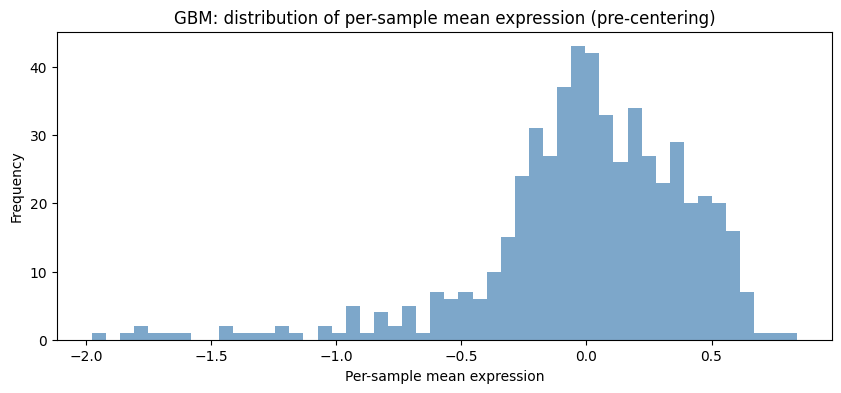


Per-sample mean after centering:
count    5.500000e+02
mean     7.684667e-19
std      3.688578e-17
min     -1.896234e-16
25%     -1.453053e-17
50%      1.634684e-18
75%      1.671011e-17
max      1.961621e-16
dtype: float64

exp_data shape: (9780, 550)
Per-sample mean (should be ~0): 7.68e-19


In [7]:
# Diagnostic: per-sample mean distribution. Removes uniform high/low shift in data
# Stand-in for per-sample quantile normalisation
sample_means = exp_data.mean(axis=0)
print("Sample mean distribution:")
print(sample_means.describe())
plt.figure(figsize=(10,4))
plt.hist(sample_means, bins=50, color='steelblue', alpha=0.7)
plt.xlabel("Per-sample mean expression")
plt.ylabel("Frequency")
plt.title(f"{CANCER}: distribution of per-sample mean expression (pre-centering)")
plt.show()

# Mean-centering 
exp_data_centered = exp_data - sample_means
print("\nPer-sample mean after centering:")
print(exp_data_centered.mean(axis=0).describe())

exp_data = exp_data_centered.copy()
print(f"\nexp_data shape: {exp_data.shape}")
print(f"Per-sample mean (should be ~0): {exp_data.mean(axis=0).mean():.2e}")

# MINER parameters (exact values matching the paper's bulk RNA-seq defaults)
min_number_genes = 6
min_correlation = 0.2
min_number_regulon_genes = 5
num_cores = 5

In [8]:
# Co-expression clustering: groups genes whose expression is correlated across a subset of patients
# THIS TAKES TIME TO RUN (~14 min for BRCA)
start = time.time()
new_clusters = miner.cluster(
    exp_data,
    minNumberGenes=min_number_genes,
    minNumberOverExpSamples=4,
    maxSamplesExcluded=0.90,
    random_state=17,
    overExpressionThreshold=80
)
elapsed = time.time() - start
print(f"Clustering completed in {elapsed/60:.1f} minutes")

sizes = pd.Series([len(c) for c in new_clusters])
print(f"\nClusters: {len(new_clusters)}")
print(sizes.describe())
print(f"Total genes: {sizes.sum()}")
print(f"Clusters > 500 genes: {(sizes > 500).sum()}")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

coexpression clustering completed in 1.24 minutes
Clustering completed in 1.2 minutes

Clusters: 747
count    747.000000
mean      16.149933
std        9.801598
min        7.000000
25%        9.000000
50%       13.000000
75%       20.000000
max       59.000000
dtype: float64
Total genes: 12064
Clusters > 500 genes: 0


In [9]:
# Refine the initial clusters (miner splits clusters whose genes are not coherently expressed in the same patients)
revised_clusters_final = miner.reviseInitialClusters(
    new_clusters,
    exp_data,
    random_state=12,
    threshold=0.925
)

sizes = pd.Series([len(v) for v in revised_clusters_final.values()])
print(f"Clusters: {len(revised_clusters_final)}")
print(f"Max: {sizes.max()}")
print(f"Median: {sizes.median():.0f}")
print(sizes.describe())
print(f"Clusters > 500 genes: {(sizes > 500).sum()}")
print(f"Clusters > 200 genes: {(sizes > 200).sum()}")
print(f"Unique genes: {sum(len(v) for v in revised_clusters_final.values())}")

Clusters: 704
Max: 224
Median: 12
count    704.000000
mean      16.803977
std       15.295894
min        7.000000
25%        9.000000
50%       12.500000
75%       19.000000
max      224.000000
dtype: float64
Clusters > 500 genes: 0
Clusters > 200 genes: 1
Unique genes: 11830


In [10]:
# Inspect clusters with > 500 genes: PC1 variance explained shows whether a big cluster is still coherent
sizes_named = pd.Series({k: len(v) for k, v in revised_clusters_final.items()})
large_clusters = sizes_named[sizes_named > 500].sort_values(ascending=False)
print("Clusters > 500 genes:")
print(large_clusters)

for cluster_key, size in large_clusters.items():
    genes = revised_clusters_final[cluster_key]
    subset = exp_data.loc[genes]
    pca_large = PCA(n_components=1)
    pca_large.fit(subset.T)
    print(f"\nCluster {cluster_key} (size {size}): PC1 variance explained = {pca_large.explained_variance_ratio_[0]:.3f}")

Clusters > 500 genes:
Series([], dtype: int64)


In [11]:
# Save the final co-expression clusters (keys as strings for JSON)
revised_clusters_final = {str(k): v for k, v in revised_clusters_final.items()}
sizes = pd.Series({k: len(v) for k, v in revised_clusters_final.items()})
print(f"Clusters: {len(revised_clusters_final)}")
print(f"Key type: {type(list(revised_clusters_final.keys())[0])}")

miner.write_json(
    revised_clusters_final,
    os.path.join(output_dir, "coexpressionDictionary.json")
)
print("saved coexpressionDictionary.json")
print(f"Final clusters: {len(revised_clusters_final)}")

Clusters: 704
Key type: <class 'str'>
saved coexpressionDictionary.json
Final clusters: 704


In [12]:
# Rebuild axes_pca once to get cluster ordering, then rebuild cluster keys as simple sorted integers
axes_pca = miner.principal_df(revised_clusters_final, exp_data, subkey=None)

revised_clusters_final = {i: v for i, (k, v) in enumerate(
    sorted(revised_clusters_final.items(), key=lambda x: int(x[0]))
)}
print(f"Keys sample: {list(revised_clusters_final.keys())[:5]}")
print(f"Key type: {type(list(revised_clusters_final.keys())[0])}")

axes_pca = miner.principal_df(revised_clusters_final, exp_data, subkey=None, minNumberGenes=6)
print(f"axes_pca shape: {axes_pca.shape}")

# Mechanistic inference: TF -> cluster assignment via TFBS + correlation
mechanistic_output = miner.mechanisticInference(
    axes_pca,
    revised_clusters_final,
    exp_data,
    correlationThreshold=min_correlation,
    numCores=num_cores,
    database_path=tfdb_path
)
print(f"Mechanistic output: {len(mechanistic_output)}")

Keys sample: [0, 1, 2, 3, 4]
Key type: <class 'int'>
axes_pca shape: (550, 704)
Mechanistic output: 629


In [13]:
# Regulons
# For each TF, the genes of each cluster it is predicted to regulate
coregulation_modules = miner.getCoregulationModules(mechanistic_output)
print(f"Coregulation modules: {len(coregulation_modules)}")

# Regulon = genes that are co-expressed AND share a binding site for the same TF (at least min_number_regulon_genes genes)
regulons = miner.getRegulons(
    coregulation_modules,
    minNumberGenes=min_number_regulon_genes,
    freqThreshold=0.333
)
print(f"Unique TF-cluster pairs: {len(regulons)}")

# regulon_modules: {regulon ID: [genes]}; regulon_df: one row per (regulon, TF, gene)
regulon_modules, regulon_df = miner.regulonDictionary(regulons)
coexpression_modules = miner.getCoexpressionModules(mechanistic_output)

regulon_sizes = pd.Series([len(genes) for tf_dict in regulons.values() for genes in tf_dict.values()])
print(f"\nRegulon size distribution:")
print(regulon_sizes.describe())
print(f"Total genes across all regulons: {regulon_sizes.sum()}")

# Eigengenes: PC1 summary of each regulon's expression
eigengenes = miner.getEigengenes(regulon_modules, exp_data, regulon_dict=None, saveFolder=None)

# Rescale eigengenes so their 95th percentile matches that of the expression data
eigen_scale = np.percentile(exp_data, 95) / np.percentile(eigengenes, 95)
eigengenes = eigen_scale * eigengenes
eigengenes.index = np.array(eigengenes.index).astype(str)
print(f"\nEigengenes shape: {eigengenes.shape}")

# Save everything
miner.write_json(mechanistic_output,   os.path.join(output_dir, "mechanisticOutput.json"))
miner.write_json(coregulation_modules, os.path.join(output_dir, "coregulationModules.json"))
miner.write_json(regulon_modules,      os.path.join(output_dir, "regulons.json"))
miner.write_json(coexpression_modules, os.path.join(output_dir, "coexpressionModules.json"))
regulon_df.to_csv(os.path.join(output_dir, "regulonDf.csv"))
eigengenes.to_csv(os.path.join(output_dir, "eigengenes.csv"))
print("Saved all mechanistic inference outputs.")

Coregulation modules: 475
Unique TF-cluster pairs: 435

Regulon size distribution:
count    3960.000000
mean       10.958586
std         8.318265
min         5.000000
25%         6.000000
50%         8.000000
75%        13.000000
max       101.000000
dtype: float64
Total genes across all regulons: 43396

Eigengenes shape: (3960, 550)
Saved all mechanistic inference outputs.


In [14]:
# Sanity check: find the largest regulon and the TF that controls it
max_size = -1
max_tf = None
max_subidx = None

for tf, sub_dict in regulons.items():
    for sub_idx, genes in sub_dict.items():
        if len(genes) > max_size:
            max_size = len(genes)
            max_tf = tf
            max_subidx = sub_idx

print(f"Largest regulon: TF={max_tf}, regulon index={max_subidx}, size={max_size}")

# Resolve to gene symbol
idmap = pd.read_csv(idmap_path, sep="\t", header=0)
gene_name_map = idmap[idmap['Source'] == 'Gene Name'][['Preferred_Name', 'Name']]
ensembl_to_symbol_lookup = dict(zip(gene_name_map['Preferred_Name'], gene_name_map['Name']))

tf_symbol = ensembl_to_symbol_lookup.get(max_tf, max_tf)
print(f"TF symbol: {tf_symbol}")

Largest regulon: TF=ENSG00000185591, regulon index=0, size=101
TF symbol: SP1


In [15]:
# Causal inference: somatic mutation -> TF (regulator) -> regulon

# Build Ensembl -> symbol mapping (same idmap source as before)
idmap = pd.read_csv(idmap_path, sep="\t", header=0)
gene_name_map = idmap[idmap['Source'] == 'Gene Name'][['Preferred_Name', 'Name']]
symbol_to_ensembl = dict(zip(gene_name_map['Name'], gene_name_map['Preferred_Name']))
ensembl_to_symbol = {v: k for k, v in symbol_to_ensembl.items()}

# miner's causal inference expects gene symbols, so convert expression and the regulon table from Ensembl IDs
exp_data_symbols = exp_data.copy()
exp_data_symbols.index = [ensembl_to_symbol.get(g, g) for g in exp_data.index]

regulon_df_symbols = regulon_df.copy()
regulon_df_symbols['Regulator'] = [ensembl_to_symbol.get(g, g) for g in regulon_df['Regulator']]
regulon_df_symbols['Gene'] = [ensembl_to_symbol.get(g, g) for g in regulon_df['Gene']]

eigengenes_symbols = eigengenes.copy()

print(f"exp_data_symbols index sample: {exp_data_symbols.index[:5].tolist()}")
print(f"regulon_df_symbols Regulator sample: {regulon_df_symbols['Regulator'].iloc[:5].tolist()}")

# Load the mutation matrix (built earlier from MC3, symbol-indexed, patient-columns)
mutation_matrix = pd.read_csv(mut_path, index_col=0)
print(f"mutation matrix: {mutation_matrix.shape}")

# Add the mutated pathways as extra rows, so they are tested exactly like genes
if config.INCLUDE_PATHWAY_MUTATIONS and os.path.exists(pathway_path):
    pathway_rows = pd.read_csv(pathway_path, index_col=0)
    mutation_matrix = pd.concat([mutation_matrix, pathway_rows.reindex(columns=mutation_matrix.columns).fillna(0).astype(int)])
    print(f"mutation matrix with pathways: {mutation_matrix.shape} ({len(pathway_rows)} pathways)")

# Align patients between mutation and expression data
common_patients = list(set(mutation_matrix.columns) & set(exp_data_symbols.columns))
print(f"common patients: {len(common_patients)}")
mutation_matrix_aligned = mutation_matrix.loc[:, common_patients]

# Run causal inference
causal_directory = os.path.join(output_dir, "causal_analysis")

# readCausalFiles reads every file in causal_directory, so results of an earlier run (possibly with a different gene list)
# are moved aside first instead of being mixed with the new ones
if os.path.isdir(causal_directory):
    previous = causal_directory + "_previous_" + time.strftime("%Y%m%d_%H%M%S")
    os.rename(causal_directory, previous)
    print(f"Earlier causal results moved to {previous}")

causalinf.causalNetworkAnalysis(
    regulon_matrix=regulon_df_symbols.copy(),
    expression_matrix=exp_data_symbols.copy(),
    reference_matrix=eigengenes_symbols.copy(),
    mutation_matrix=mutation_matrix_aligned.copy(),
    resultsDirectory=causal_directory,
    minRegulons=1,
    significance_threshold=0.05,
    causalFolder="causal_results_somatic"
)

causal_results = causalinf.readCausalFiles(causal_directory)
causal_results.to_csv(os.path.join(output_dir, "completeCausalResults.csv"))
print(f"total causal flows: {causal_results.shape[0]}")
causal_results.head()

exp_data_symbols index sample: ['AACS', 'FSTL1', 'ELMO2', 'CREB3L1', 'RPS11']
regulon_df_symbols Regulator sample: ['ERF', 'ERF', 'ERF', 'ERF', 'ERF']
mutation matrix: (44, 350)
mutation matrix with pathways: (235, 350) (191 pathways)
common patients: 350
Earlier causal results moved to data\gbm\gbm_output\causal_analysis_previous_20261006_221149
completed causal analysis in 2.78 minutes
total causal flows: 27354


,Mutation,Regulator,Regulon,MutationRegulatorEdge,-log10(p)_MutationRegulatorEdge,RegulatorRegulon_Spearman_R,RegulatorRegulon_Spearman_p-value,Regulon_stratification_t-statistic,-log10(p)_Regulon_stratification,Fraction_of_edges_correctly_aligned,Fraction_of_aligned_and_diff_exp_edges,number_downstream_regulons,number_differentially_expressed_regulons
3643,AHNAK2,IRF4,R-3643,-1.0,2.323865,0.765481,5.214322e-107,-2.540291,1.729117,1.0,0.333333,9,3
3649,AHNAK2,IRF4,R-3649,-1.0,2.323865,-0.445307,3.802857e-28,3.970687,3.323063,1.0,0.333333,9,3
3645,AHNAK2,IRF4,R-3645,-1.0,2.323865,-0.454441,2.214296e-29,2.077273,1.305558,1.0,0.333333,9,3
2250,AHNAK2,CTCF,R-2250,1.0,3.190833,0.408032,1.767632e-23,3.945680,3.232338,1.0,0.315789,19,6
2243,AHNAK2,CTCF,R-2243,1.0,3.190833,0.386153,5.320508e-21,2.258005,1.462004,1.0,0.315789,19,6


In [16]:
# Background distribution for statistical testing (upper/lower/middle tertiles)

bkgd = miner.background_df(exp_data)

# Overactive: genes coherently in upper third of expression distribution
overexpressed_members = miner.biclusterMembershipDictionary(
    regulon_modules, bkgd, label=2, p=0.05
)
# Underactive: genes coherently in lower third
underexpressed_members = miner.biclusterMembershipDictionary(
    regulon_modules, bkgd, label=0, p=0.05
)

# Convert to incidence matrices (regulons x patients)
over_matrix  = miner.membershipToIncidence(overexpressed_members,  exp_data)
under_matrix = miner.membershipToIncidence(underexpressed_members, exp_data)

over_matrix.to_csv(os.path.join(output_dir,  "overExpressedMembers.csv"))
under_matrix.to_csv(os.path.join(output_dir, "underExpressedMembers.csv"))

print(f"Over matrix shape:  {over_matrix.shape}")
print(f"Under matrix shape: {under_matrix.shape}")

Over matrix shape:  (3960, 550)
Under matrix shape: (3960, 550)


In [17]:
# Transcriptional states: groups of patients with similar regulon activity

# Reload the saved quantization matrices
over_matrix  = pd.read_csv(os.path.join(output_dir, "overExpressedMembers.csv"),  index_col=0)
under_matrix = pd.read_csv(os.path.join(output_dir, "underExpressedMembers.csv"), index_col=0)

# Rebuild the membership dictionaries from the matrices (exact recovery, matrices are binary)
overexpressed_members  = miner.matrix_to_dictionary(over_matrix,  threshold=0.5)
underexpressed_members = miner.matrix_to_dictionary(under_matrix, threshold=0.5)

print("over_matrix:", over_matrix.shape)
print("under_matrix:", under_matrix.shape)
print("overexpressed_members keys:", len(overexpressed_members))
print("underexpressed_members keys:", len(underexpressed_members))

# Regulon activity = over - under: 1 (overactive), 0 (neutral), -1 (underactive)
reference_matrix     = over_matrix - under_matrix
primary_matrix        = over_matrix
primary_dictionary     = overexpressed_members
secondary_matrix       = under_matrix
secondary_dictionary   = underexpressed_members

# A state must contain at least 1% of patients (minClusterSize)
states, centroid_clusters = inferSubtypes(
    reference_matrix, primary_matrix, secondary_matrix,
    primary_dictionary, secondary_dictionary,
    minClusterSize=int(np.ceil(0.01 * over_matrix.shape[1])),   # <- no exp_data needed
    restricted_index=None)

# Save as {state number: [patient IDs]}
transcriptional_states = {str(i): states[i] for i in range(len(states))}
with open(os.path.join(output_dir, "transcriptional_states.json"), 'w') as f:
    json.dump(transcriptional_states, f)

print(f"Number of states: {len(transcriptional_states)}")
print(f"State sizes: {[len(s) for s in states]}")

over_matrix: (3960, 550)
under_matrix: (3960, 550)
overexpressed_members keys: 3960
underexpressed_members keys: 3960
completed subtype inference in 0.31 minutes
Number of states: 24
State sizes: [38, 37, 20, 20, 18, 8, 53, 21, 10, 6, 33, 14, 13, 31, 48, 18, 28, 25, 15, 47, 11, 12, 15, 9]


In [18]:
# Certain states have size <5, inspecting these:
# THIS TAKES TIME TO RUN

eigengenes = pd.read_csv(os.path.join(output_dir, "eigengenes.csv"), index_col=0)
eigengenes.columns = eigengenes.columns.astype(str)
all_patients = eigengenes.columns.tolist()

np.random.seed(42)
n_null_iter = 200

results = []
for state_id, patients in transcriptional_states.items():
    patients = [p for p in patients if p in eigengenes.columns]
    n = len(patients)
    if n < 2:
        results.append({'state': state_id, 'n_patients': n, 'within_corr': np.nan,
                         'null_mean': np.nan, 'null_std': np.nan, 'z_score': np.nan})
        continue

    # within-state mean pairwise correlation (off-diagonal)
    corr_mat = eigengenes[patients].corr().values
    within_corr = np.mean(corr_mat[np.triu_indices(n, k=1)])

    # null: same-size random patient sets from the full cohort
    null_means = []
    for _ in range(n_null_iter):
        rand_patients = np.random.choice(all_patients, size=n, replace=False)
        rand_corr = eigengenes[rand_patients].corr().values
        null_means.append(np.mean(rand_corr[np.triu_indices(n, k=1)]))
    null_means = np.array(null_means)

    z = (within_corr - null_means.mean()) / null_means.std()
    results.append({
        'state': state_id, 'n_patients': n,
        'within_corr': within_corr,
        'null_mean': null_means.mean(), 'null_std': null_means.std(),
        'z_score': z
    })

coherence_df = pd.DataFrame(results).set_index('state').sort_values('n_patients')
pd.set_option('display.max_rows', None)
print(coherence_df)

coherence_df.to_csv(os.path.join(output_dir, "state_coherence_check.csv"))

       n_patients  within_corr  null_mean  null_std    z_score
state                                                         
9               6     0.545223   0.007077  0.069404   7.753834
5               8     0.429482  -0.004365  0.053204   8.154382
23              9     0.109235   0.001779  0.050974   2.108057
8              10     0.413984   0.003400  0.049328   8.323626
20             11     0.262685  -0.001525  0.038894   6.793148
21             12     0.451812  -0.002026  0.035056  12.945966
12             13     0.590002   0.000298  0.034357  17.163908
11             14     0.402765  -0.000677  0.031801  12.686356
18             15     0.384763   0.002718  0.030723  12.435171
22             15     0.355901   0.000808  0.030086  11.802696
15             18     0.375696   0.001282  0.024801  15.096510
4              18     0.473038   0.002294  0.026034  18.082095
2              20     0.386406   0.001463  0.022442  17.152790
3              20     0.238992   0.000632  0.020015  11

Number of programs: 194
Program sizes (regulon counts): [78, 77, 64, 63, 53, 50, 42, 37, 33, 31, 30, 28, 27, 26, 25, 22, 22, 21, 21, 20, 20, 19, 18, 18, 16, 16, 15, 15, 14, 14, 6, 60, 49, 37, 30, 27, 23, 22, 20, 18, 18, 16, 15, 14, 14, 13, 12, 12, 12, 11, 11, 11, 10, 10, 10, 9, 9, 7, 7, 7, 6, 5, 5, 86, 70, 31, 30, 16, 16, 15, 5, 36, 31, 25, 21, 20, 19, 17, 17, 16, 16, 13, 12, 11, 10, 41, 33, 28, 22, 21, 20, 18, 18, 10, 8, 8, 6, 37, 33, 30, 29, 26, 23, 21, 19, 17, 17, 16, 16, 13, 13, 12, 11, 11, 10, 9, 7, 7, 5, 5, 33, 26, 25, 24, 22, 21, 20, 19, 18, 18, 16, 15, 14, 13, 12, 12, 11, 10, 9, 8, 8, 7, 7, 6, 5, 5, 49, 39, 36, 31, 27, 27, 24, 20, 20, 18, 16, 13, 9, 8, 8, 7, 40, 31, 28, 27, 26, 25, 25, 24, 24, 22, 22, 21, 21, 21, 21, 21, 18, 17, 17, 17, 16, 16, 14, 14, 11, 10, 9, 8, 6, 5, 15, 8]


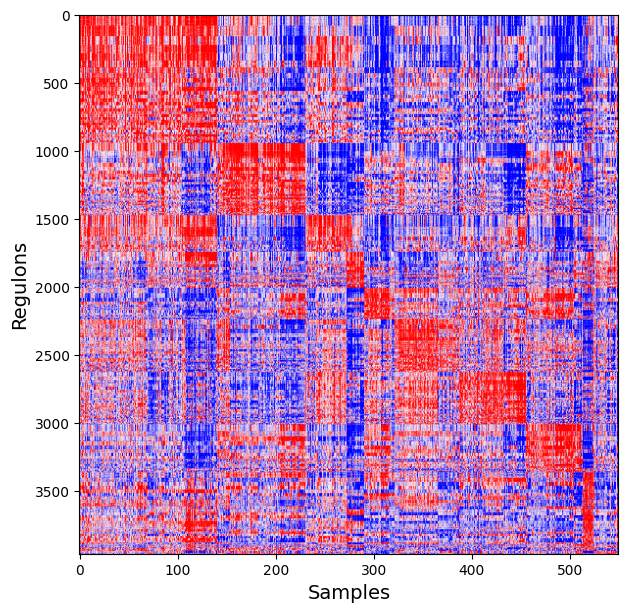

In [19]:
# Reloading needed files from memory
eigengenes = pd.read_csv(os.path.join(output_dir, "eigengenes.csv"), index_col=0)
eigengenes.index = np.array(eigengenes.index).astype(str)

with open(os.path.join(output_dir, "regulons.json")) as f:
    regulon_modules = json.load(f)

reference_df = eigengenes.copy()

# Transcriptional programs: groups of regulons with similar activity across patients
programs, _ = miner.mosaic(
    dfr=reference_df,
    clusterList=centroid_clusters,
    minClusterSize_x=int(np.ceil(0.01 * over_matrix.shape[1])),
    minClusterSize_y=5,
    allow_singletons=False,
    max_groups=50,
    saveFile=os.path.join(output_dir, "regulon_activity_heatmap.pdf"),
    random_state=12
)

# Convert to {program number: [regulon IDs]} and save
transcriptional_programs_obj, program_regulons = miner.transcriptionalPrograms(programs, regulon_modules)
program_list = [program_regulons[("").join(["TP", str(i)])] for i in range(len(program_regulons))]
programs_dictionary = {str(i): program_list[i] for i in range(len(program_list))}

with open(os.path.join(output_dir, "transcriptional_programs.json"), 'w') as f:
    json.dump(programs_dictionary, f)

print(f"Number of programs: {len(programs_dictionary)}")
print(f"Program sizes (regulon counts): {[len(p) for p in program_list]}")

mosaic_df shape: (3960, 550)
states_df shape: (194, 550)


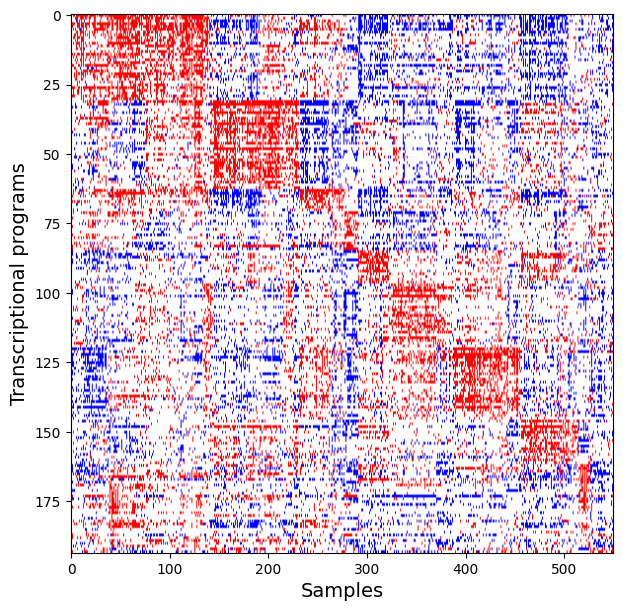

In [20]:
# regulons_activity_heatmap.csv = eigengenes reordered by program/state membership
mosaic_df = reference_df.loc[np.hstack(program_list), np.hstack(states)]
mosaic_df.to_csv(os.path.join(output_dir, "regulons_activity_heatmap.csv"))

# Quantised regulon activity: 1 = overactive, 0 = neutral, -1 = underactive, in the same row / column order as the heatmap
activity_df = over_matrix - under_matrix
activity_df.index = activity_df.index.astype(str)
activity_df = activity_df.loc[np.hstack(program_list), np.hstack(states)]

# Summarise to one row per program: a program is overactive (1) in a patient if the net share of its regulons that are
# overactive is at least stateThreshold, underactive (-1) if it is at most -stateThreshold. miner's reduceModules expects
# the quantised matrix here; an earlier version of this notebook passed the continuous eigengenes instead
states_df = miner.reduceModules(
    df=activity_df,
    programs=program_list,
    states=states,
    stateThreshold=0.50,
    saveFile=os.path.join(output_dir, "transcriptional_programs.pdf")
)

print("mosaic_df shape:", mosaic_df.shape)
print("states_df shape:", states_df.shape)


programs_vs_states shape: (194, 24)


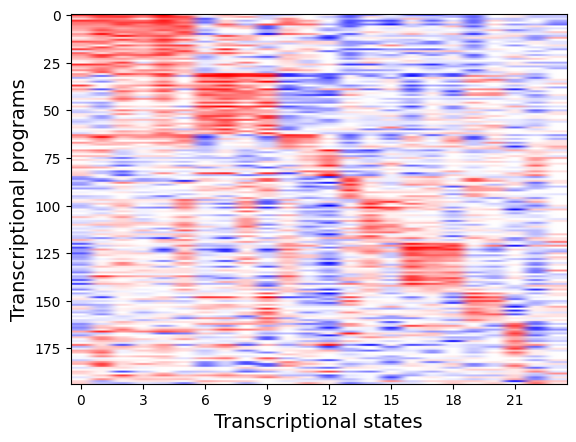

In [21]:
# Program activity in each state (programs x states), saved as csv and pdf
programs_vs_states_df = miner.programsVsStates(
    states_df, states,
    filename=os.path.join(output_dir, "programs_vs_states.pdf"),
    csvpath=os.path.join(output_dir, "programs_vs_states.csv"),
    showplot=True
)

print("programs_vs_states shape:", programs_vs_states_df.shape)

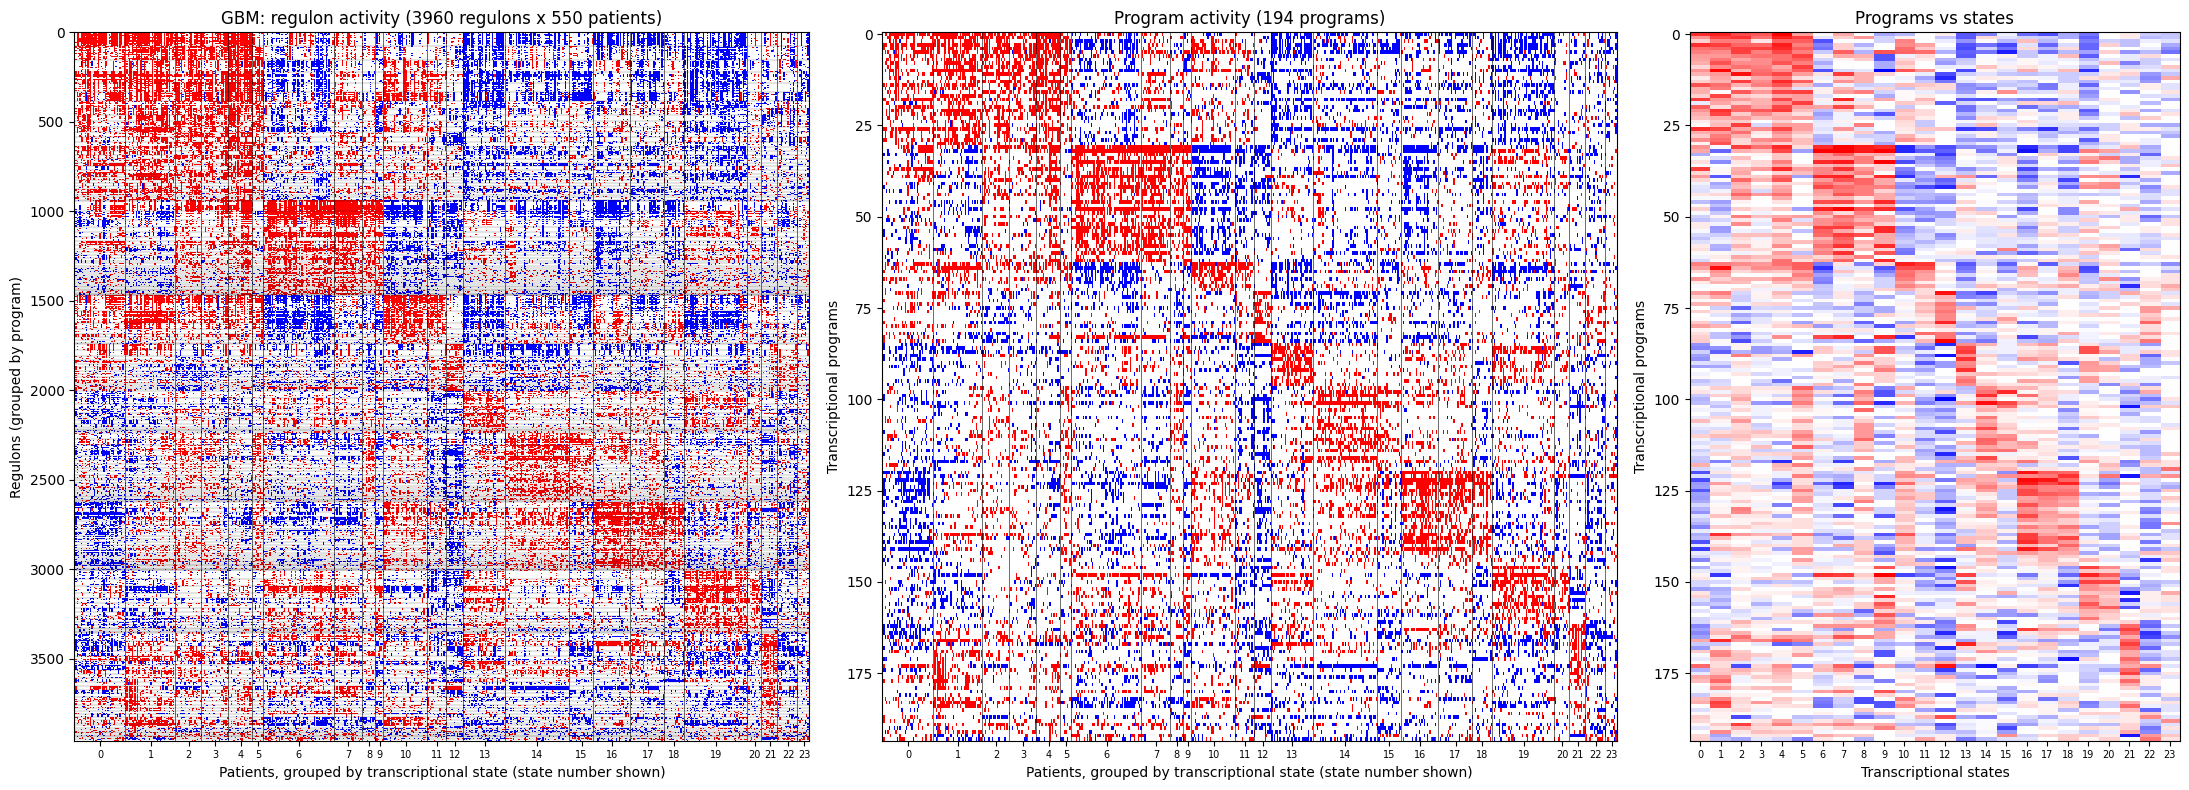

In [22]:
# Sharper versions of the three summary plots, as drawn in the paper's Figure 1A: three colours only
# (red = overactive, white = neutral, blue = underactive), no smoothing between cells, and a line at every state boundary
state_sizes = [len(s) for s in states]
state_edges = np.cumsum(state_sizes)
state_mids  = state_edges - np.array(state_sizes) / 2
program_edges = np.cumsum([len(p) for p in program_list])

fig, axes = plt.subplots(1, 3, figsize=(22, 8), gridspec_kw={"width_ratios": [1.2, 1.2, 0.8]})

# Regulons x patients, quantised
axes[0].imshow(activity_df.values, cmap="bwr", vmin=-1, vmax=1, aspect="auto", interpolation="nearest")
axes[0].set_title(f"{CANCER}: regulon activity ({activity_df.shape[0]} regulons x {activity_df.shape[1]} patients)")
axes[0].set_ylabel("Regulons (grouped by program)")

# Programs x patients
axes[1].imshow(states_df.values, cmap="bwr", vmin=-1, vmax=1, aspect="auto", interpolation="nearest")
axes[1].set_title(f"Program activity ({states_df.shape[0]} programs)")
axes[1].set_ylabel("Transcriptional programs")

for ax in axes[:2]:
    for edge in state_edges[:-1]:
        ax.axvline(edge - 0.5, color="black", linewidth=0.4)
    ax.set_xticks(state_mids)
    ax.set_xticklabels(range(len(states)), fontsize=7)
    ax.set_xlabel("Patients, grouped by transcriptional state (state number shown)")
for edge in program_edges[:-1]:
    axes[0].axhline(edge - 0.5, color="black", linewidth=0.15)

# Programs x states: share of each state's patients in which the program is over- (red) or under-active (blue)
axes[2].imshow(programs_vs_states_df.values, cmap="bwr", vmin=-1, vmax=1, aspect="auto", interpolation="nearest")
axes[2].set_title("Programs vs states")
axes[2].set_xticks(range(len(states)))
axes[2].set_xticklabels(range(len(states)), fontsize=7)
axes[2].set_xlabel("Transcriptional states")
axes[2].set_ylabel("Transcriptional programs")

plt.tight_layout()
plt.savefig(os.path.join(output_dir, "activity_summary_quantised.png"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(output_dir, "activity_summary_quantised.pdf"), bbox_inches="tight")
plt.show()


### Filter causal results (paper criteria)

A causal flow is retained only if ALL four conditions are met (same as GBM `03_run_miner`):
1. Regulon is differentially active w.r.t. the mutation
2. Regulator is differentially expressed w.r.t. the mutation
3. Regulator is significantly correlated to the regulon
4. ≥50% of downstream edges are directionally consistent

In [23]:
# Self-contained: reloads completeCausalResults.csv so the 14-min clustering above doesn't need to be rerun
causal_results = pd.read_csv(os.path.join(output_dir, "completeCausalResults.csv"), index_col=0)

filtered = causal_results[
    causal_results["-log10(p)_Regulon_stratification"] >= -np.log10(0.05)
]
filtered = filtered[filtered["Fraction_of_edges_correctly_aligned"] >= 0.5]
filtered = filtered[filtered["RegulatorRegulon_Spearman_p-value"] <= 0.05]
filtered = filtered[
    filtered["-log10(p)_MutationRegulatorEdge"] >= -np.log10(0.05)
]

filtered.to_csv(os.path.join(output_dir, "filteredCausalResults.csv"))
print(f"Unfiltered causal flows: {causal_results.shape[0]}")
print(f"Filtered causal flows: {filtered.shape[0]}")
print(f"Unique mutations: {filtered['Mutation'].nunique()}")
print(f"Unique regulators: {filtered['Regulator'].nunique()}")
print(f"Unique regulons: {filtered['Regulon'].nunique()}")

# Number of causal flows per mutated gene; the known drivers of this cancer should be near the top
print("\nCausal flows per mutation:")
print(filtered['Mutation'].value_counts().to_string())

# BRCA reference (checked against the saved completeCausalResults.csv):
# 17249 -> 16640 flows | 19 mutations | 401 regulators | 4958 regulons
# NOTE: TTN, USH2A, MUC16, RYR2, FLG, DMD, NEB, SYNE1, HMCN1, SPTA1, ZFHX4 are long genes that are frequently
# mutated as passengers (driven by tumour mutation burden, not selection). They pass the 5% filter, so their
# flows are kept here to match the GBM run, but treat them with caution when interpreting.

Unfiltered causal flows: 27354
Filtered causal flows: 26986
Unique mutations: 205
Unique regulators: 293
Unique regulons: 2472

Causal flows per mutation:
Mutation
ATRX                                     1042
IDH1                                     1022
PID_MYC_ACTIV_PATHWAY                     822
PID_BARD1_PATHWAY                         799
TP53                                      784
PID_P53_REGULATION_PATHWAY                773
PID_HDAC_CLASSIII_PATHWAY                 759
PID_HIF1A_PATHWAY                         750
PID_AURORA_A_PATHWAY                      735
PID_LKB1_PATHWAY                          711
PID_AP1_PATHWAY                           580
PID_P38_ALPHA_BETA_DOWNSTREAM_PATHWAY     561
PID_ILK_PATHWAY                           537
PID_REG_GR_PATHWAY                        523
NF1                                       496
PID_P53_DOWNSTREAM_PATHWAY                417
PID_P75_NTR_PATHWAY                       368
PID_MET_PATHWAY                           317
PID_ERBB

## miRNA regulators (extension towards the paper's miRNA layer)

In the paper a regulon can be controlled by a transcription factor **or a miRNA**, and causal flows run mutation → miRNA → regulon. The paper finds miRNA regulators with the FIRM pipeline. FIRM is not used here; this section uses the miRNA target sets that ship with miner (`mirna.pkl`: 221 miRNA seed families, each with its predicted target genes):

1. **Target enrichment.** For every co-expression cluster and miRNA family: are the family's targets over-represented in the cluster (hypergeometric p < 0.05, at least 2 genes)? Same test miner uses for TF binding sites.
2. **miRNA regulons.** The enriched target genes of a cluster form a regulon (same miner functions and size rule as for TFs).
3. **Negative correlation.** A miRNA of the family must be expressed and negatively correlated with the regulon eigengene (Spearman R ≤ −0.2, p ≤ 0.05), since miRNAs repress their targets.
4. **Causal flows.** Same tests as miner's causal step: the mutation changes the miRNA's expression, changes the regulon's activity, and the three signs agree. miner's own function cannot be used because it only tests regulators that are themselves genes inside a regulon, which a miRNA never is.

Only patients with miRNA data are used (RNA-seq-era samples, about 245). Everything is written to separate `mirna_*` files; the TF results above are not changed. Needs `gbm_mirna_log2rpm.csv` from `01b_gbm_mirna`.


In [24]:
# miRNA expression and the miRNA families of miner's target database
from scipy import stats as sstats

mirna_path = os.path.join(data_dir, f"{prefix}_mirna_log2rpm.csv")
HAS_MIRNA  = os.path.exists(mirna_path)

def family_members(family_key, available):

    '''

    Finds the miRNAs of the expression matrix that belong to one seed family of miner's target database.

    Args: family_key (str). Database key: seed sequence, then member names, e.g. "ACATTCC_MIR1_MIR206" or "GTAAACC_MIR2995P"
          available (set of str). miRNA names of the expression matrix without the copy number, e.g. "hsa-mir-125b", "hsa-let-7a"

    Returns: list of str. Matching names. Old names are resolved where possible (MIR124A -> hsa-mir-124, MIR103 -> hsa-mir-103a)

    '''

    found = []
    for token in family_key.split("_")[1:]:
        # Drop the arm (3P / 5P): expression is measured per precursor
        if token.endswith(("3P", "5P")):
            token = token[:-2]
        kind = "let" if token.startswith("LET") else "mir"
        match = re.fullmatch(r"(\d+)([A-Z]?)(\d?)", token[3:])
        if match is None:
            continue
        number, letter, _ = match.groups()
        candidates = [f"hsa-{kind}-{number}{letter.lower()}"]
        if letter:
            candidates.append(f"hsa-{kind}-{number}")       # letter dropped since (MIR124A -> mir-124)
        else:
            candidates.append(f"hsa-{kind}-{number}a")      # letter added since (MIR103 -> mir-103a)
        for name in candidates:
            if name in available:
                found.append(name)
                break
    return sorted(set(found))

if HAS_MIRNA:
    import re
    mirna_log = pd.read_csv(mirna_path, index_col=0)

    # Copies of the same precursor (hsa-let-7a-1, -2, -3) are averaged into one row (hsa-let-7a)
    base_names = mirna_log.index.str.replace(r"^(hsa-(?:mir|let)-\d+[a-z]*)-\d+$", r"\1", regex=True)
    mirna_log = mirna_log.groupby(base_names).mean()

    # Keep miRNAs detected (at least 1 read per million) in at least half of the samples, and patients with expression data
    detected = (mirna_log >= 1).mean(axis=1) >= 0.5
    mirna_patients = [p for p in mirna_log.columns if p in exp_data.columns]
    mirna_expr = mirna_log.loc[detected, mirna_patients]
    print(f"miRNAs: {len(mirna_log)} -> {len(mirna_expr)} detected | patients with miRNA and expression data: {len(mirna_patients)}")

    # miner's database: {family key: [Ensembl IDs of predicted targets]}
    mirna_db = miner.read_pkl(os.path.join(miner_dir, "data", "network_dictionaries", "mirna.pkl"))
    family_to_mirnas = {fam: family_members(fam, set(mirna_expr.index)) for fam in mirna_db}
    family_to_mirnas = {fam: members for fam, members in family_to_mirnas.items() if members}
    print(f"miRNA families in the database: {len(mirna_db)} | with at least one detected miRNA: {len(family_to_mirnas)}")
else:
    print(f"{prefix}_mirna_log2rpm.csv not found (run 01b_gbm_mirna first): the miRNA section is skipped")


miRNAs: 1484 -> 416 detected | patients with miRNA and expression data: 245
miRNA families in the database: 221 | with at least one detected miRNA: 158


In [25]:
# miRNA regulons: clusters enriched for a family's targets, whose eigengene is negatively correlated with a miRNA of that family
MIRNA_MAX_R = -0.2

if HAS_MIRNA:
    clusters   = miner.read_json(os.path.join(output_dir, "coexpressionDictionary.json"))
    background = set(exp_data.index)
    n_background = len(background)

    # 1. Target enrichment, in the structure miner uses for TFs: {cluster: {regulator: [p, overlapping genes]}}
    mirna_mechanistic = {}
    for fam in family_to_mirnas:
        targets = set(mirna_db[fam]) & background
        if len(targets) < 2:
            continue
        for cluster_id, genes in clusters.items():
            overlap = targets & set(genes)
            if len(overlap) < 2:
                continue
            # Probability of an overlap this large or larger by chance
            p = sstats.hypergeom.sf(len(overlap) - 1, n_background, len(targets), len(genes))
            if p < 0.05:
                mirna_mechanistic.setdefault(cluster_id, {})[fam] = [p, sorted(overlap)]
    print(f"Clusters enriched for at least one miRNA family: {len(mirna_mechanistic)} / {len(clusters)}")

    # 2. Regulons, with the same miner functions and size rule as for TFs
    mirna_coregulation = miner.getCoregulationModules(mirna_mechanistic)
    mirna_regulons = miner.getRegulons(mirna_coregulation, minNumberGenes=min_number_regulon_genes, freqThreshold=0.333)
    assert len(mirna_regulons) > 0, "no cluster is enriched for the targets of any detected miRNA family"
    mirna_modules, mirna_regulon_df = miner.regulonDictionary(mirna_regulons)
    mirna_regulon_df = mirna_regulon_df.rename(columns={"Regulator": "Family"})
    print(f"Candidate miRNA regulons (family x gene set): {len(mirna_modules)}")

    # Eigengenes on the same scale as the TF regulons
    mirna_eigengenes = miner.getEigengenes(mirna_modules, exp_data, regulon_dict=None, saveFolder=None)
    mirna_eigengenes = (np.percentile(exp_data, 95) / np.percentile(mirna_eigengenes, 95)) * mirna_eigengenes
    mirna_eigengenes.index = np.array(mirna_eigengenes.index).astype(str)

    # 3. Negative correlation: for each regulon keep the family's most negatively correlated miRNA, if it passes
    family_of = mirna_regulon_df.drop_duplicates("Regulon_ID").set_index("Regulon_ID")["Family"]
    rows = []
    for regulon_id, fam in family_of.items():
        eigen = mirna_eigengenes.loc[str(regulon_id), mirna_patients]
        tests = [(m,) + tuple(sstats.spearmanr(mirna_expr.loc[m], eigen)) for m in family_to_mirnas[fam]]
        best = min(tests, key=lambda t: t[1])
        rows.append({"Regulon_ID": str(regulon_id), "Family": fam, "Regulator": best[0], "Spearman_R": best[1], "Spearman_p": best[2],
                     "n_genes": len(mirna_modules[str(regulon_id)])})
    mirna_regulon_table = pd.DataFrame(rows).set_index("Regulon_ID")
    passed = mirna_regulon_table[(mirna_regulon_table["Spearman_R"] <= MIRNA_MAX_R) & (mirna_regulon_table["Spearman_p"] <= 0.05)]
    print(f"miRNA regulons with a negatively correlated miRNA (R <= {MIRNA_MAX_R}, p <= 0.05): {len(passed)} / {len(mirna_regulon_table)} "
          f"| miRNAs: {passed['Regulator'].nunique()}")

    # Keep the passing regulons and save
    mirna_modules    = {r: g for r, g in mirna_modules.items() if r in passed.index}
    mirna_regulon_df = mirna_regulon_df[mirna_regulon_df["Regulon_ID"].astype(str).isin(passed.index)].copy()
    mirna_regulon_df["Regulator"] = mirna_regulon_df["Regulon_ID"].astype(str).map(passed["Regulator"])
    mirna_eigengenes = mirna_eigengenes.loc[passed.index]

    miner.write_json(mirna_modules, os.path.join(output_dir, "mirna_regulons.json"))
    mirna_regulon_df.to_csv(os.path.join(output_dir, "mirna_regulonDf.csv"))
    mirna_eigengenes.to_csv(os.path.join(output_dir, "mirna_eigengenes.csv"))
    passed.to_csv(os.path.join(output_dir, "mirna_regulon_regulators.csv"))
    print(passed.sort_values("Spearman_R").head(15).round(3).to_string())


Clusters enriched for at least one miRNA family: 376 / 704
Candidate miRNA regulons (family x gene set): 98
miRNA regulons with a negatively correlated miRNA (R <= -0.2, p <= 0.05): 15 / 98 | miRNAs: 14
                                                                   Family     Regulator  Spearman_R  Spearman_p  n_genes
Regulon_ID                                                                                                              
93                                                  ACTGTGA_MIR27A_MIR27B   hsa-mir-27a      -0.385       0.000        5
73                                                  AATGTGA_MIR23A_MIR23B   hsa-mir-23a      -0.336       0.000        7
40                                         CAGTATT_MIR200B_MIR200C_MIR429  hsa-mir-200c      -0.326       0.000        5
87                                                        TGCCTTA_MIR124A   hsa-mir-124      -0.297       0.000        5
82          CTACCTC_LET7A_LET7B_LET7C_LET7D_LET7E_LET7F_MIR98_LET7G_LET

In [26]:
# Causal flows mutation -> miRNA -> regulon, with the same tests and output columns as miner's causal step

def mirna_causal_flows(mutations, regulator_expr, eigen, regulon_table, significance=0.05):

    '''

    Tests every (mutation, miRNA) pair the way miner tests (mutation, TF) pairs.

    Args: mutations (df), genes x patients. 1 = mutated, 0 = wild type
          regulator_expr (df), miRNAs x patients. miRNA expression
          eigen (df), regulons x patients. Regulon eigengenes
          regulon_table (df), index = regulon ID. Columns Regulator, Spearman_R, Spearman_p (miRNA vs eigengene)
          significance (float). p-value threshold of the two t-tests (default 0.05)

    Returns: df, one row per causal flow, columns as in miner's completeCausalResults.csv. A flow is reported if the miRNA is
             differentially expressed between mutated and wild-type patients, the regulon eigengene is too, and the signs
             agree: (mutation effect on miRNA) x (miRNA-regulon correlation) x (mutation effect on regulon) > 0

    '''

    flows = []
    regulons_of = regulon_table.groupby("Regulator").groups
    for mutation in mutations.index:
        mutated = mutations.columns[mutations.loc[mutation] == 1]
        wild    = mutations.columns[mutations.loc[mutation] == 0]
        if len(mutated) < 3 or len(wild) < 3:
            continue

        # Welch t-tests of mutated vs wild type, for every miRNA and every regulon at once
        t_reg, p_reg = sstats.ttest_ind(regulator_expr[mutated], regulator_expr[wild], equal_var=False, axis=1)
        t_eig, p_eig = sstats.ttest_ind(eigen[mutated], eigen[wild], equal_var=False, axis=1)
        t_reg, p_reg = pd.Series(t_reg, index=regulator_expr.index), pd.Series(p_reg, index=regulator_expr.index)
        t_eig, p_eig = pd.Series(t_eig, index=eigen.index), pd.Series(p_eig, index=eigen.index)

        for regulator, regulon_ids in regulons_of.items():
            if not p_reg[regulator] <= significance:
                continue
            regulon_ids = list(regulon_ids)
            different = [r for r in regulon_ids if p_eig[r] <= significance]
            aligned = [r for r in different if t_reg[regulator] * regulon_table.loc[r, "Spearman_R"] * t_eig[r] > 0]
            for r in aligned:
                flows.append({
                    "Mutation": mutation, "Regulator": regulator, "Regulon": f"MR-{r}",
                    "MutationRegulatorEdge": np.sign(t_reg[regulator]),
                    "-log10(p)_MutationRegulatorEdge": -np.log10(p_reg[regulator]),
                    "RegulatorRegulon_Spearman_R": regulon_table.loc[r, "Spearman_R"],
                    "RegulatorRegulon_Spearman_p-value": regulon_table.loc[r, "Spearman_p"],
                    "Regulon_stratification_t-statistic": t_eig[r],
                    "-log10(p)_Regulon_stratification": -np.log10(p_eig[r]),
                    "Fraction_of_edges_correctly_aligned": len(aligned) / len(different),
                    "Fraction_of_aligned_and_diff_exp_edges": len(aligned) / len(regulon_ids),
                    "number_downstream_regulons": len(regulon_ids),
                    "number_differentially_expressed_regulons": len(different),
                })
    return pd.DataFrame(flows)

if HAS_MIRNA and len(passed) > 0:
    # Patients with mutation, miRNA and expression data
    mutation_matrix = pd.read_csv(mut_path, index_col=0)

    # Add the mutated pathways as extra rows, so they are tested exactly like genes
    if config.INCLUDE_PATHWAY_MUTATIONS and os.path.exists(pathway_path):
        pathway_rows = pd.read_csv(pathway_path, index_col=0)
        mutation_matrix = pd.concat([mutation_matrix, pathway_rows.reindex(columns=mutation_matrix.columns).fillna(0).astype(int)])
        print(f"mutation matrix with pathways: {mutation_matrix.shape} ({len(pathway_rows)} pathways)")
    causal_patients = [p for p in mirna_patients if p in mutation_matrix.columns]
    print(f"Patients with mutation, miRNA and expression data: {len(causal_patients)}")

    mirna_causal = mirna_causal_flows(mutation_matrix[causal_patients], mirna_expr[causal_patients],
                                      mirna_eigengenes[causal_patients], passed)
    mirna_causal.to_csv(os.path.join(output_dir, "mirna_completeCausalResults.csv"), index=False)
    print(f"miRNA causal flows: {len(mirna_causal)}")

    if len(mirna_causal) > 0:
        # Same four criteria as for the TF flows
        mirna_filtered = mirna_causal[
            (mirna_causal["-log10(p)_Regulon_stratification"] >= -np.log10(0.05))
            & (mirna_causal["Fraction_of_edges_correctly_aligned"] >= 0.5)
            & (mirna_causal["RegulatorRegulon_Spearman_p-value"] <= 0.05)
            & (mirna_causal["-log10(p)_MutationRegulatorEdge"] >= -np.log10(0.05))]
        mirna_filtered.to_csv(os.path.join(output_dir, "mirna_filteredCausalResults.csv"), index=False)
        print(f"Filtered miRNA causal flows: {len(mirna_filtered)} | mutations: {mirna_filtered['Mutation'].nunique()} | "
              f"miRNAs: {mirna_filtered['Regulator'].nunique()} | regulons: {mirna_filtered['Regulon'].nunique()}")
        print("\nFlows per mutation:")
        print(mirna_filtered["Mutation"].value_counts().head(15).to_string())
        print("\nFlows per miRNA:")
        print(mirna_filtered["Regulator"].value_counts().head(15).to_string())


mutation matrix with pathways: (235, 350) (191 pathways)
Patients with mutation, miRNA and expression data: 223
miRNA causal flows: 83
Filtered miRNA causal flows: 83 | mutations: 41 | miRNAs: 12 | regulons: 13

Flows per mutation:
Mutation
IDH1                         6
PID_SYNDECAN_2_PATHWAY       6
NF1                          5
PID_ATF2_PATHWAY             5
PID_RAS_PATHWAY              4
PID_MYC_ACTIV_PATHWAY        3
PTEN                         3
TP53                         3
PID_HIF1A_PATHWAY            3
PID_AURORA_A_PATHWAY         3
PID_HDAC_CLASSIII_PATHWAY    3
PID_AP1_PATHWAY              3
PID_IL6_7_PATHWAY            2
ATRX                         2
PID_CXCR3_PATHWAY            2

Flows per miRNA:
Regulator
hsa-mir-221     15
hsa-mir-200c    13
hsa-mir-27a     11
hsa-let-7c      10
hsa-mir-130b     6
hsa-mir-9        6
hsa-mir-23a      6
hsa-mir-125b     6
hsa-mir-330      5
hsa-mir-15b      2
hsa-mir-15a      2
hsa-mir-124      1
